In [ ]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam, SGD  # optimizer
from tensorflow.keras.callbacks import Callback
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
from collections import Counter

DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

for split, folder in SPLITS.items():
    sizes, modes, skipped = Counter(), Counter(), []
    for root, _, files in os.walk(os.path.join(DATA_DIR, folder)):
        for f in files:
            if not f.lower().endswith(IMG_EXT):
                skipped.append(f)                  
                continue
            with Image.open(os.path.join(root, f)) as img:
                sizes[img.size] += 1               # PIL size is (width, height)
                modes[img.mode] += 1               # 'L' = grayscale, 'RGB' = colour

    print(f"------------- {split} ({sum(sizes.values())} images) -------------")
    for (w, h), n in sizes.most_common():
        print(f"  {w} x {h} (W x H): {n} images")
    print(f"  colour modes: {dict(modes)}")
    if skipped:
        print(f"  skipped {len(skipped)} non-image files, e.g. {skipped[:3]}")

------------- train (436 images) -------------
  64 x 60 (W x H): 436 images
  colour modes: {'L': 436}
------------- val (93 images) -------------
  64 x 60 (W x H): 93 images
  colour modes: {'L': 93}
------------- test (95 images) -------------
  64 x 60 (W x H): 95 images
  colour modes: {'L': 95}


In [4]:
# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["straight", "left", "right", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


In [5]:
# Standardize using training-set statistics only (same as Model B)
X_mean, X_std = X_train.mean(), X_train.std()
print(f"Train mean={X_mean:.4f}, std={X_std:.4f}")

X_train_n = (X_train - X_mean) / X_std
X_val_n   = (X_val   - X_mean) / X_std
X_test_n  = (X_test  - X_mean) / X_std

print("Normalised train mean/std:", X_train_n.mean().round(4), X_train_n.std().round(4))

Train mean=0.2753, std=0.2529
Normalised train mean/std: 0.0 1.0


split  total         straight             left            right               up
train    436     109 ( 25.0%)     105 ( 24.1%)     113 ( 25.9%)     109 ( 25.0%)
val       93      26 ( 28.0%)      25 ( 26.9%)      23 ( 24.7%)      19 ( 20.4%)
test      95      21 ( 22.1%)      27 ( 28.4%)      19 ( 20.0%)      28 ( 29.5%)


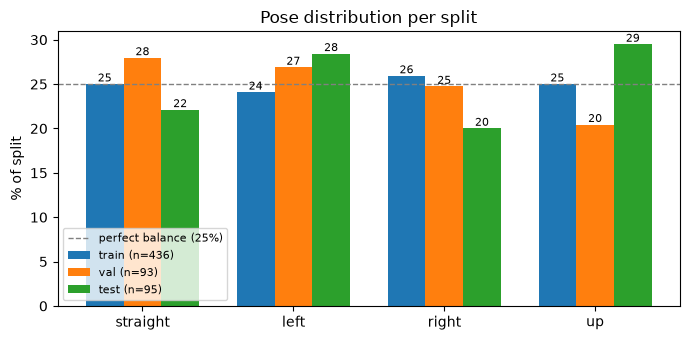

In [6]:
splits = {"train": y_train, "val": y_val, "test": y_test}

# Table of counts and percentages per pose
print(f"{'split':6s} {'total':>5s}  " + "  ".join(f"{c:>15s}" for c in CLASSES))
for name, y in splits.items():
    counts = np.bincount(y, minlength=NUM_CLASSES)
    pct = 100 * counts / counts.sum()
    cells = "  ".join(f"{n:4d} ({p:5.1f}%)".rjust(15) for n, p in zip(counts, pct))
    print(f"{name:6s} {len(y):5d}  {cells}")

# Grouped bar chart of the percentages
x = np.arange(NUM_CLASSES)
width = 0.25
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (name, y) in enumerate(splits.items()):
    pct = 100 * np.bincount(y, minlength=NUM_CLASSES) / len(y)
    bars = ax.bar(x + (k - 1) * width, pct, width, label=f"{name} (n={len(y)})")
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.axhline(25, color="gray", linestyle="--", linewidth=1, label="perfect balance (25%)")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("% of split")
ax.set_title("Pose distribution per split")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [8]:
# building model A (same structure as Model B, but with standard convolutions)

def conv_block(filters, pool=True):
    block = [
        layers.Conv2D(filters, 3, padding="same", use_bias=False,   # BN supplies the bias/shift
                      kernel_initializer="he_normal"),
        layers.BatchNormalization(momentum=0.9),
        layers.ReLU(),
    ]
    if pool:
        block.append(layers.MaxPooling2D(2))
    return block

def build_model_A():
    keras.utils.set_random_seed(SEED)   # same initial weights on every call
    return models.Sequential([
        layers.Input(shape=(60, 64, 1)),

        *conv_block(32),
        *conv_block(64),
        *conv_block(128),
        *conv_block(128, pool=False),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ], name="Model_A")


from tensorflow.keras.callbacks import ReduceLROnPlateau

def train(optimizer, epochs, batch_size=32, verbose=0):
    model = build_model_A()
    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    timer = EpochTimer()
    reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                  patience=5, min_lr=1e-5)
    history = model.fit(X_train_n, y_train,
                        validation_data=(X_val_n, y_val),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=[timer, reduce_lr], verbose=verbose)
    return model, history, timer

build_model_A().summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 60, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 60, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 60, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 30, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 15, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,828 (975.89 KB)

 Trainable params: 249,124 (973.14 KB)

 Non-trainable params: 704 (2.75 KB)

In [9]:
EPOCHS = 100

model_A, history_A, timer_A = train(Adam(1e-3), epochs=EPOCHS, verbose=1)
time_per_epoch_A = np.mean(timer_A.times[1:])   # skip epoch 1 (one-off setup)
print(f"Average time per epoch: {time_per_epoch_A:.3f} s")
model_A.summary()

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 86ms/step - accuracy: 0.4220 - loss: 1.2868 - val_accuracy: 0.5054 - val_loss: 1.1174 - learning_rate: 0.0010
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.6927 - loss: 0.9093 - val_accuracy: 0.7204 - val_loss: 1.0367 - learning_rate: 0.0010
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.9312 - loss: 0.5283 - val_accuracy: 0.6452 - val_loss: 1.1807 - learning_rate: 0.0010
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.9656 - loss: 0.2981 - val_accuracy: 0.4624 - val_loss: 1.3214 - learning_rate: 0.0010
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9771 - loss: 0.1632 - val_accuracy: 0.7634 - val_loss: 0.5052 - learning_rate: 0.0010
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9885 - loss: 0.1011 - val_accuracy: 0.9892 - val_loss: 0.0942 - learning_rate: 0.0010
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.9931 - loss: 0.0731 - 

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 60, 64, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 60, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 60, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 30, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 30, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 15, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 15, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 15, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 7, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 7, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 748,078 (2.85 MB)

 Trainable params: 249,124 (973.14 KB)

 Non-trainable params: 704 (2.75 KB)

 Optimizer params: 498,250 (1.90 MB)

In [10]:
# parameter calculation

trainable     = sum(int(np.prod(w.shape)) for w in model_A.trainable_weights)
non_trainable = sum(int(np.prod(w.shape)) for w in model_A.non_trainable_weights)
total = trainable + non_trainable

print(f"Trainable params:     {trainable:,}")
print(f"Non-trainable params: {non_trainable:,}")
print(f"Total params:         {total:,}")

Trainable params:     249,124
Non-trainable params: 704
Total params:         249,828


In [11]:
def count_macs(model):
    # Multiply-accumulates of Conv2D and Dense layers.
    total = 0
    for layer in model.layers:
        if isinstance(layer, layers.Conv2D):
            _, h, w, c_out = layer.output.shape          # output height, width, channels
            kh, kw = layer.kernel_size
            c_in = layer.input.shape[-1]
            macs = h * w * kh * kw * c_in * c_out        # one k*k*C_in dot product per output value
        elif isinstance(layer, layers.Dense):
            macs = layer.input.shape[-1] * layer.units
        else:
            continue
        total += macs
        print(f"{layer.name:8s} {macs:>12,}")
    print(f"{'TOTAL':8s} {total:>12,}  (~{total / 1e6:.2f} M MACs per image)")
    return total

macs_a = count_macs(model_A)

conv2d_4    1,105,920
conv2d_5   17,694,720
conv2d_6   17,694,720
conv2d_7    8,257,536
dense_2         8,192
dense_3           256
TOTAL      44,761,344  (~44.76 M MACs per image)


In [ ]:
import io, zipfile, h5py

def size_on_disk_kb(model, path):
    clean = model.__class__.from_config(model.get_config())   # same architecture, NOT compiled → no optimizer
    clean.set_weights(model.get_weights())                    # copy the trained weights
    clean.save(path)

    # sanity check: the saved file must not contain optimizer state
    with zipfile.ZipFile(path) as z, h5py.File(io.BytesIO(z.read("model.weights.h5")), "r") as f:
        assert "optimizer" not in f, "optimizer state found in saved file"

    return os.path.getsize(path) / 1024

size_kb_A = size_on_disk_kb(model_A, "model_A.keras")
print(f"Model A size on disk: {size_kb_A:.1f} KB")
print(f"FP32 weights estimate: {model_A.count_params() * 4 / 1024:.1f} KB")   # sanity check

np.savez("model_A_norm_stats.npz", mean=X_mean, std=X_std)   # needed to preprocess new images

Model A size on disk: 1040.3 KB
FP32 weights estimate: 975.9 KB


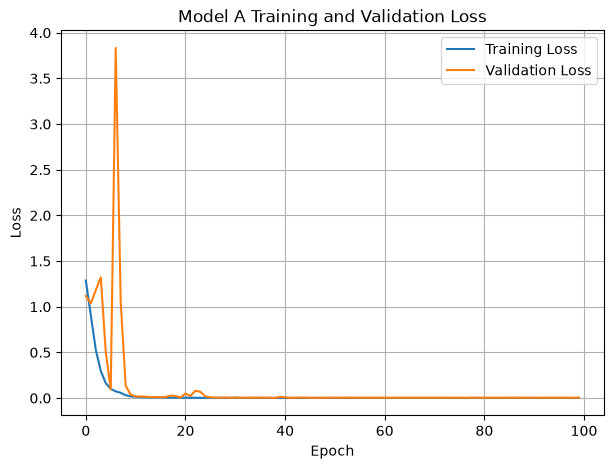

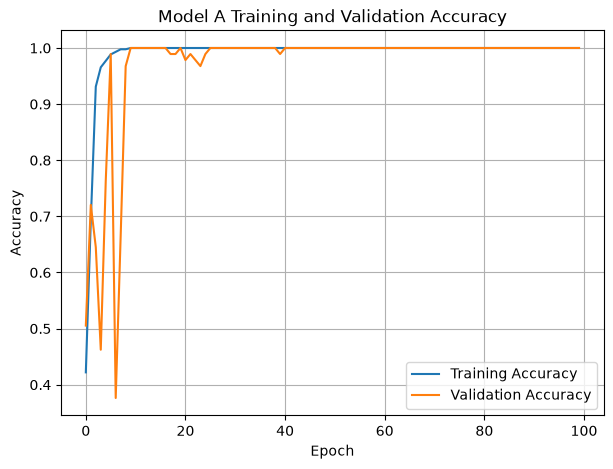

In [13]:
# plot model A training and validation loss and accuracy

plt.figure(figsize=(7,5))
plt.plot(history_A.history["loss"], label="Training Loss")
plt.plot(history_A.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(history_A.history["accuracy"], label="Training Accuracy")
plt.plot(history_A.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9895 - loss: 0.0950
Test Accuracy: 98.95%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


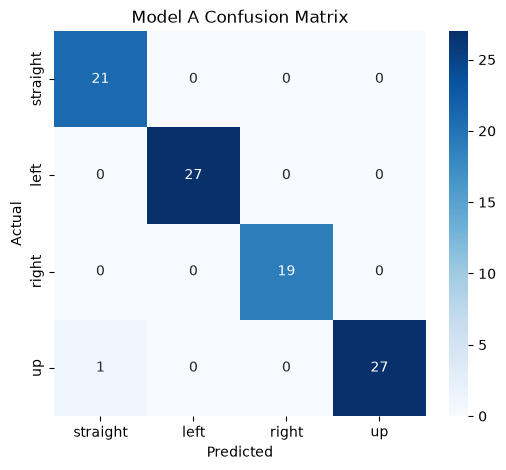

              precision    recall  f1-score   support

    straight     0.9545    1.0000    0.9767        21
        left     1.0000    1.0000    1.0000        27
       right     1.0000    1.0000    1.0000        19
          up     1.0000    0.9643    0.9818        28

    accuracy                         0.9895        95
   macro avg     0.9886    0.9911    0.9896        95
weighted avg     0.9900    0.9895    0.9895        95



In [14]:
# plot confusion matrix and classification report for model A

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


test_loss, test_accuracy = model_A.evaluate(X_test_n, y_test, verbose=1)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

y_pred = np.argmax(model_A.predict(X_test_n), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model A Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))

In [15]:
optimizers = {
    "Adam (lr=1e-3)":               lambda: Adam(learning_rate=1e-3),
    "SGD (lr=5e-2)":                lambda: SGD(learning_rate=5e-2),
    "SGD + momentum 0.9 (lr=1e-2)": lambda: SGD(learning_rate=1e-2, momentum=0.9),
}

opt_results = {}
for name, make_opt in optimizers.items():
    print(f"Training with {name} ...")
    model, history, timer = train(make_opt(), epochs=EPOCHS)
    test_loss, test_acc = model.evaluate(X_test_n, y_test, verbose=0)
    opt_results[name] = {"history": history.history,
                         "test_acc": test_acc,
                         "sec_per_epoch": np.mean(timer.times[1:])}

Training with Adam (lr=1e-3) ...
Training with SGD (lr=5e-2) ...
Training with SGD + momentum 0.9 (lr=1e-2) ...


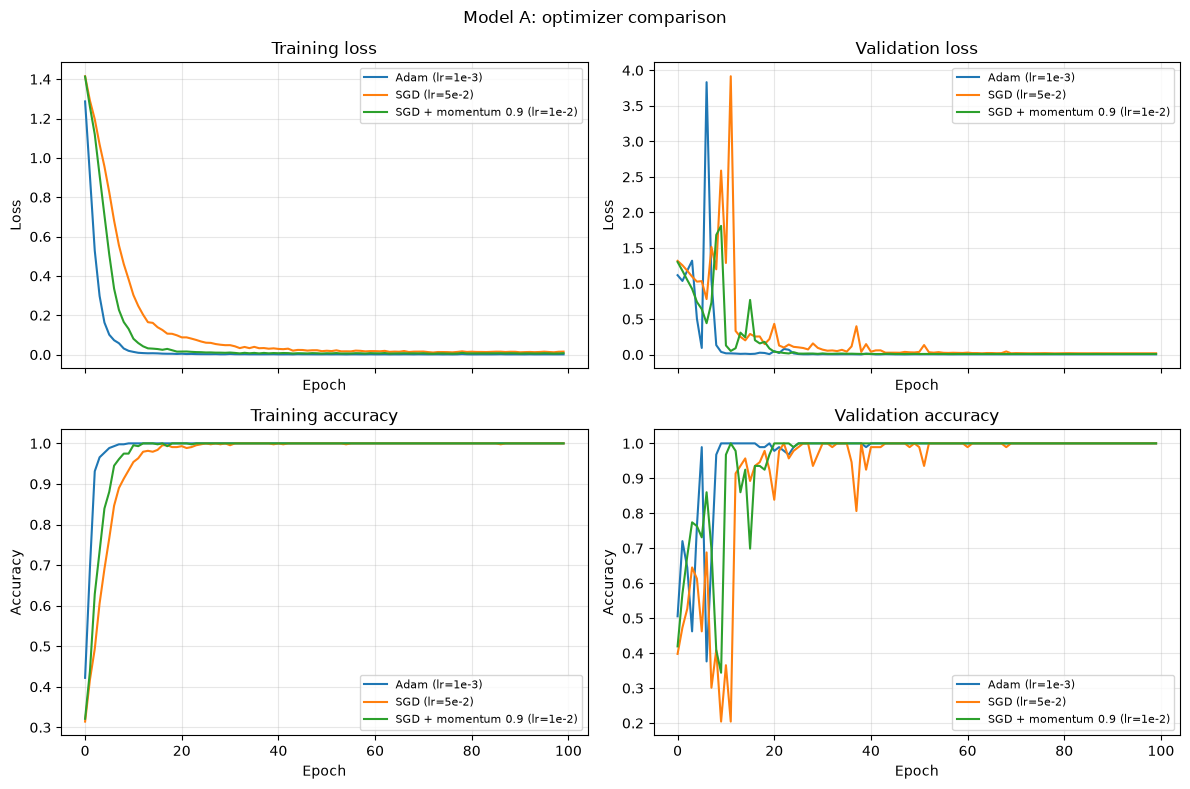

Optimizer                        best val acc  epoch to 90% val  test acc  s/epoch
Adam (lr=1e-3)                          1.000                 6     0.989    2.388
SGD (lr=5e-2)                           1.000                13     0.968    1.480
SGD + momentum 0.9 (lr=1e-2)            1.000                11     0.979    1.553


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for name, r in opt_results.items():
    h = r["history"]
    axes[0, 0].plot(h["loss"], label=name)
    axes[0, 1].plot(h["val_loss"], label=name)
    axes[1, 0].plot(h["accuracy"], label=name)
    axes[1, 1].plot(h["val_accuracy"], label=name)

titles = [["Training loss", "Validation loss"],
          ["Training accuracy", "Validation accuracy"]]
for i in range(2):
    for j in range(2):
        axes[i, j].set_title(titles[i][j])
        axes[i, j].set_xlabel("Epoch")
        axes[i, j].set_ylabel("Loss" if i == 0 else "Accuracy")
        axes[i, j].grid(alpha=0.3)
        axes[i, j].legend(fontsize=8)
plt.suptitle("Model A: optimizer comparison")
plt.tight_layout()
plt.show()

# Summary table for the report
print(f"{'Optimizer':32s} {'best val acc':>12s} {'epoch to 90% val':>17s} {'test acc':>9s} {'s/epoch':>8s}")
for name, r in opt_results.items():
    va = np.array(r["history"]["val_accuracy"])
    hit = np.argmax(va >= 0.90) + 1 if (va >= 0.90).any() else "never"
    print(f"{name:32s} {va.max():12.3f} {str(hit):>17s} {r['test_acc']:9.3f} {r['sec_per_epoch']:8.3f}")

lr=1e-2, m=0.0   best val acc 1.000   epoch to 90%: 33
lr=1e-2, m=0.5   best val acc 1.000   epoch to 90%: 17
lr=1e-2, m=0.9   best val acc 1.000   epoch to 90%: 11
lr=1e-2, m=0.99  best val acc 1.000   epoch to 90%: 11


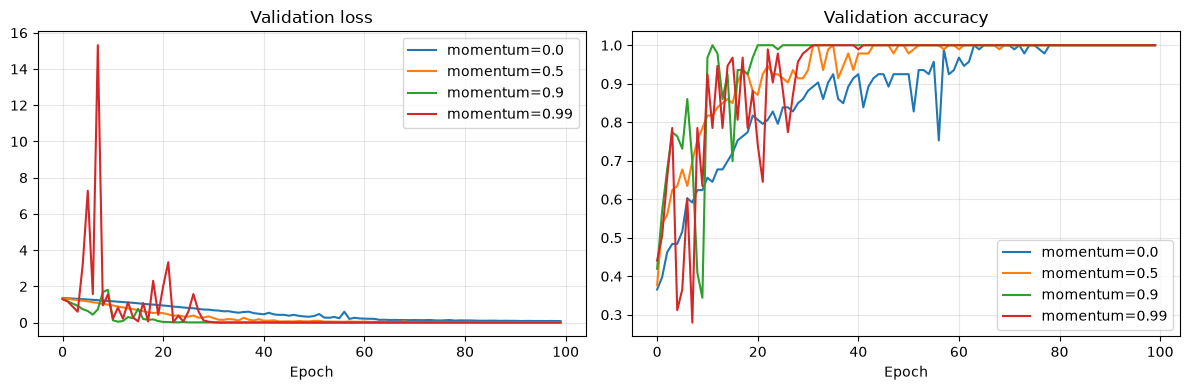

In [17]:
momentum_runs = {}

for m in [0.0, 0.5, 0.9, 0.99]:
    _, h, _ = train(
        SGD(learning_rate=1e-2, momentum=m),
        epochs=EPOCHS
    )
    momentum_runs[m] = h.history

    val_acc = h.history["val_accuracy"]
    best_acc = max(val_acc)

    # First epoch where validation accuracy reaches 90%
    epoch_90 = next(
        (epoch + 1 for epoch, acc in enumerate(val_acc) if acc >= 0.90),
        None
    )

    epoch_str = epoch_90 if epoch_90 is not None else "never"

    print(
        f"lr=1e-2, m={m:<5} "
        f"best val acc {best_acc:.3f}   "
        f"epoch to 90%: {epoch_str}"
    )

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for m, h in momentum_runs.items():
    ax1.plot(h["val_loss"], label=f"momentum={m}")
    ax2.plot(h["val_accuracy"], label=f"momentum={m}")

ax1.set_title("Validation loss")
ax2.set_title("Validation accuracy")

for ax in (ax1, ax2):
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()